conda install -c conda-forge xlrd -y   
conda install scipy

# Import Library that Used

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

from scipy.optimize import differential_evolution
from scipy.spatial.distance import cdist

# Read the Data

In [2]:
columns = [
    "cement_kg_per_m3",
    "blast_furnace_slag_kg_per_m3",
    "fly_ash_kg_per_m3",
    "water_kg_per_m3",
    "superplasticizer_kg_per_m3",
    "coarse_aggregate_kg_per_m3",
    "fine_aggregate_kg_per_m3",
    "age_days",
    "compressive_strength_mpa",
]

raw_df = pd.read_excel("data/Concrete_Data.xls")
raw_df.columns = columns
raw_df.to_csv("data/q2_concrete_compressive_strength.csv", index=False)

/tmp/ipykernel_58662/2338757167.py:13: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  raw_df = pd.read_excel("data/Concrete_Data.xls")


In [ ]:
df = pd.read_csv("data/q2_concrete_compressive_strength.csv")
df.head()

,cement_kg_per_m3,blast_furnace_slag_kg_per_m3,fly_ash_kg_per_m3,water_kg_per_m3,superplasticizer_kg_per_m3,coarse_aggregate_kg_per_m3,fine_aggregate_kg_per_m3,age_days,compressive_strength_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


| Column | Unit | Meaning |
|---|---|---|
| cement_kg_per_m3 | kg/m³ | Main binder (decision variable) |
| blast_furnace_slag_kg_per_m3 | kg/m³ | By-product binder, partial cement replacement (decision variable) |
| fly_ash_kg_per_m3 | kg/m³ | By-product binder, partial cement replacement (decision variable) |
| water_kg_per_m3 | kg/m³ | Water (decision variable) |
| superplasticizer_kg_per_m3 | kg/m³ | Additive that lets less water be used (decision variable) |
| coarse_aggregate_kg_per_m3 | kg/m³ | Gravel or crushed stone (decision variable) |
| fine_aggregate_kg_per_m3 | kg/m³ | Sand (decision variable) |
| age_days | days | Age at testing, fixed at 28 for recommendations |
| **compressive_strength_mpa** | MPa | **Target. Measured crushing strength** |

From this table, these are my assumption for each variable

1. cement_kg_per_m3 (Included - Decision Variable): We assume the materials team controls this amount when designing a mix. It is the main glue that holds the concrete together, and our goal is to make this number as small as possible while keeping the concrete strong.   

2. blast_furnace_slag_kg_per_m3 (Included - Decision Variable): We assume the team can freely add this industrial by-product to replace part of the cement. It helps build concrete strength over time without needing as much expensive cement.

3. fly_ash_kg_per_m3 (Included - Decision Variable): We assume the team can freely add this coal by-product as another partial cement replacement. Like slag, it helps the concrete gain strength at 28 days while lowering cement use.

4. water_kg_per_m3 (Included - Decision Variable): We assume the team sets the exact water weight before mixing. Water starts the chemical hardening process, though adding too much water weakens the final concrete.   

5. superplasticizer_kg_per_m3 (Included - Decision Variable): We assume the team can add this chemical liquid to keep wet concrete easy to pour even when using less water. We assume it is available in the lab without inventing cost or workability limits.   

6. coarse_aggregate_kg_per_m3 (Included - Decision Variable): We assume the team chooses the weight of gravel or crushed stone in the mix. It makes up the heavy solid body of the concrete.

7. fine_aggregate_kg_per_m3 (Included - Decision Variable): We assume the team chooses the weight of sand in the mix. It fills the small spaces between the coarse gravel and binder paste.   

8. age_days (Included - Fixed at 28 for Recommendations): We assume the model can learn from concrete tested at all curing ages in the dataset, but when searching for new mixes, we lock this value at 28 days because every candidate mix must be crushed after 28 days in the lab.

9. compressive_strength_mpa (Target): We assume the lab crushing machine measured the concrete strength accurately in megapascals (MPa). We also assume all test batches used consistent material quality and standard lab curing conditions, and that a recommended mix must reach at least 40 MPa at 28 days to pass.

# Preprocessing

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   cement_kg_per_m3              1030 non-null   float64
 1   blast_furnace_slag_kg_per_m3  1030 non-null   float64
 2   fly_ash_kg_per_m3             1030 non-null   float64
 3   water_kg_per_m3               1030 non-null   float64
 4   superplasticizer_kg_per_m3    1030 non-null   float64
 5   coarse_aggregate_kg_per_m3    1030 non-null   float64
 6   fine_aggregate_kg_per_m3      1030 non-null   float64
 7   age_days                      1030 non-null   int64  
 8   compressive_strength_mpa      1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


From here we can see that there is no missing value from the data.

Total rows : 1030   
Total columns: 9

In [5]:
print(df.duplicated().sum())

25


In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.duplicated().sum())

0


After removing the 25 exact duplicate rows from the original 1,030 rows, we have 1,005 valid test records.

In [10]:
# Check duplicate ingredient recipes tested at the exact same age
recipe_age_cols = columns[:-1]
print(
    "Duplicate (7 ingredients + age_days) rows:",
    df.duplicated(subset=recipe_age_cols).sum(),
)

Duplicate (7 ingredients + age_days) rows: 9


There are 9 rows with the exact same 7 ingredients and age_days, but slightly different compressive_strength_mpa values. These are replicate lab tests (crushing multiple cylinders from the same concrete batch) and represent natural experimental lab noise, so we keep them.

In [11]:
# Check how many rows are at age = 28 days vs other ages
print("\nRow count by age_days:")
print(df["age_days"].value_counts().sort_index())


Row count by age_days:
age_days
1        2
3      129
7      122
14      62
28     419
56      86
90      54
91      17
100     52
120      3
180     26
270     13
360      6
365     14
Name: count, dtype: int64


Out of 1,005 rows, 419 rows were tested at age_days = 28, while the remaining 586 rows were tested at other ages (from 1 day to 365 days). 

In [9]:
df.describe()

,cement_kg_per_m3,blast_furnace_slag_kg_per_m3,fly_ash_kg_per_m3,water_kg_per_m3,superplasticizer_kg_per_m3,coarse_aggregate_kg_per_m3,fine_aggregate_kg_per_m3,age_days,compressive_strength_mpa
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.629055,72.043134,55.535075,182.074378,6.031647,974.376468,772.686617,45.856716,35.250273
std,104.345003,86.170555,64.207448,21.340740,5.919559,77.579534,80.339851,63.734692,16.284808
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,190.680000,0.000000,0.000000,166.610000,0.000000,932.000000,724.300000,7.000000,23.523542
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.798114
75%,349.000000,142.500000,118.270000,192.940000,10.000000,1031.000000,822.200000,56.000000,44.868340
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [12]:
ingredient_cols = [
    "cement_kg_per_m3",
    "blast_furnace_slag_kg_per_m3",
    "fly_ash_kg_per_m3",
    "water_kg_per_m3",
    "superplasticizer_kg_per_m3",
    "coarse_aggregate_kg_per_m3",
    "fine_aggregate_kg_per_m3",
]

# Create recipe_id for identical 7-ingredient mixes
df["recipe_id"] = df.groupby(ingredient_cols).ngroup()
print("Total unique 7-ingredient recipes:", df["recipe_id"].nunique())


Total unique 7-ingredient recipes: 428


In [13]:
# Group-aware train/test split (80% train recipes, 20% test recipes)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df["recipe_id"]))
train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

overlap = set(train["recipe_id"]).intersection(set(test["recipe_id"]))
print(
    f"Train shape: {train.shape} ({train['recipe_id'].nunique()} recipes | 28-day"
    f" rows: {(train['age_days'] == 28).sum()})"
)
print(
    f"Test shape:  {test.shape} ({test['recipe_id'].nunique()} recipes | 28-day"
    f" rows: {(test['age_days'] == 28).sum()})"
)
print("Overlapping recipes between train and test:", len(overlap))

Train shape: (810, 10) (342 recipes | 28-day rows: 334)
Test shape:  (195, 10) (86 recipes | 28-day rows: 85)
Overlapping recipes between train and test: 0


The clean dataset has 1,005 rows. The split puts 810 rows (80%) into the training set and 195 rows (20%) into the test set. Both sets have 10 columns: the 9 original columns plus the new recipe_id column.

The training set has 342 unique recipes, and 334 rows are from 28-day tests. The test set has 86 unique recipes, and 85 rows are from 28-day tests. Both sets have a similar share of 28-day tests, which makes the model evaluation fair.

Zero recipes appear in both the training set and the test set. In this dataset, the same concrete recipe is often tested at many ages, such as 7 days, 28 days, and 90 days. Grouping by recipe_id keeps all age tests for one recipe in the same set. This stops data leakage. The model cannot cheat by learning a recipe at 7 days and guessing the same recipe at 28 days. Because of this, the test score shows how well the model predicts completely new recipes.

In [14]:
# Summary statistics on training set (for EDA & data-derived bounds)
print("\nTraining Set Summary Statistics:")
print(train.drop(columns=["recipe_id"]).describe().round(2).to_string())


Training Set Summary Statistics:
       cement_kg_per_m3  blast_furnace_slag_kg_per_m3  fly_ash_kg_per_m3  water_kg_per_m3  superplasticizer_kg_per_m3  coarse_aggregate_kg_per_m3  fine_aggregate_kg_per_m3  age_days  compressive_strength_mpa
count            810.00                        810.00             810.00           810.00                      810.00                      810.00                    810.00    810.00                    810.00
mean             280.32                         75.59              51.55           182.39                        5.68                      977.04                    768.83     45.75                     35.30
std              102.39                         88.63              64.28            21.00                        5.83                       76.60                     79.73     64.09                     16.32
min              108.30                          0.00               0.00           121.75                        0.00                 

# EDA 

We use train_28 for the first two plots (28-Day Strength vs. Cement and 28-Day Strength vs. Water-to-Binder Ratio) so we can see how ingredients affect 28-day strength specifically, without mixing in 3-day or 365-day measurements, which would confuse the picture since curing age strongly changes strength.

In [15]:
# Filter training set to 28-day rows for decision-focused checks
train_28 = train[train["age_days"] == 28].copy()

# Create helpful domain ratios for EDA (do NOT add as raw features yet unless needed)
train_28["total_binder"] = (
    train_28["cement_kg_per_m3"]
    + train_28["blast_furnace_slag_kg_per_m3"]
    + train_28["fly_ash_kg_per_m3"]
)
train_28["water_binder_ratio"] = (
    train_28["water_kg_per_m3"] / train_28["total_binder"]
)
train_28["total_mass"] = train_28[ingredient_cols].sum(axis=1)

In [ ]:
# Print existing 28-day mixes in the entire clean dataset that already meet >= 40 MPa
all_28_passing = df[
    (df["age_days"] == 28) & (df["compressive_strength_mpa"] >= 40.0)
].sort_values("cement_kg_per_m3")
print(f"Total 28-day rows meeting >= 40 MPa in full dataset: {len(all_28_passing)}")
print("\nTop 5 Lowest-Cement Existing Mixes Meeting >= 40 MPa at 28 Days:")
print(
    all_28_passing[ingredient_cols + ["compressive_strength_mpa"]]
    .head(5)
    .round(2)
)

Total 28-day rows meeting >= 40 MPa in full dataset: 141

Top 5 Lowest-Cement Existing Mixes Meeting >= 40 MPa at 28 Days:
     cement_kg_per_m3  blast_furnace_slag_kg_per_m3  fly_ash_kg_per_m3  water_kg_per_m3  superplasticizer_kg_per_m3  coarse_aggregate_kg_per_m3  fine_aggregate_kg_per_m3  compressive_strength_mpa
975            141.90                         166.6             129.70           173.50                       10.90                       882.6                     785.3                     44.61
818            142.00                         167.0             130.00           174.00                       11.00                       883.0                     785.0                     44.61
409            165.00                         128.5             132.10           175.06                        8.08                      1005.8                     746.6                     46.39
414            167.00                          75.4             167.00           164.03      

Out of 419 tests at 28 days in the clean dataset, 141 mixes already reach the 40 MPa target strength.

The lowest-cement existing mix that reaches 40 MPa uses 141.90 kg/m³ of cement and achieves 44.61 MPa at 28 days. (Row 818 is nearly the same recipe rounded to whole numbers at 142.00 kg/m³). This is choosen as baseline.

All top 5 low-cement mixes replace a large share of cement with blast furnace slag (75 to 167 kg/m³) and fly ash (128 to 167 kg/m³), while adding superplasticizer (7.8 to 11.0 kg/m³) to keep water low (164 to 175 kg/m³). This gives us a clear target: our recommended mixes should aim to beat 141.90 kg/m³ of cement while safely reaching >= 40 MPa.

In [ ]:
# Print data-derived physical ratios on training set (for realistic constraints)
train_all_mass = train[ingredient_cols].sum(axis=1)
train_all_binder = (
    train["cement_kg_per_m3"]
    + train["blast_furnace_slag_kg_per_m3"]
    + train["fly_ash_kg_per_m3"]
)
train_all_wb = train["water_kg_per_m3"] / train_all_binder

print("\nTraining Set Total Mass (kg/m3) quantiles:")
print(train_all_mass.quantile([0.0, 0.01, 0.05, 0.5, 0.95, 0.99, 1.0]).round(2))


Training Set Total Mass (kg/m3) quantiles:
0.00    2194.6
0.01    2210.0
0.05    2229.0
0.50    2344.0
0.95    2448.8
0.99    2463.0
1.00    2551.0
dtype: float64

Training Set Water-to-Binder Ratio quantiles:
0.00    0.235
0.01    0.270
0.05    0.293
0.50    0.468
0.95    0.672
0.99    0.780
1.00    0.822
dtype: float64


In the training data, 90% of all concrete mixes (from the 5th to 95th percentile) weigh between 2,229.0 kg/m³ and 2,448.8 kg/m³, with a middle value (median) of 2,344.0 kg/m³.

Why matter: One cubic meter of concrete has a fixed physical volume. If the optimizer picks tiny amounts of every ingredient (for example, summing to 1,500 kg/m³) or huge amounts (3,000 kg/m³), the mix would not fill 1 m³ properly. Constraining the sum of the 7 ingredients to stay between 2,229 and 2,449 kg/m³ (the central 90% of training data) keeps every candidate recipe physically realistic.

In [18]:
print("\nTraining Set Water-to-Binder Ratio quantiles:")
print(train_all_wb.quantile([0.0, 0.01, 0.05, 0.5, 0.95, 0.99, 1.0]).round(3))


Training Set Water-to-Binder Ratio quantiles:
0.00    0.235
0.01    0.270
0.05    0.293
0.50    0.468
0.95    0.672
0.99    0.780
1.00    0.822
dtype: float64


In the training data, 90% of mixes have a water-to-binder ratio between 0.293 and 0.672, with a median of 0.468.

Total binder is cement + slag + fly ash. If water is too high relative to total binder (above 0.67), the concrete becomes weak and watery, if water is too low (below 0.29), the mix is too dry to mix properly in the lab. Keeping this ratio inside the data-derived range (0.29 to 0.67) prevents unrealistic recipes.

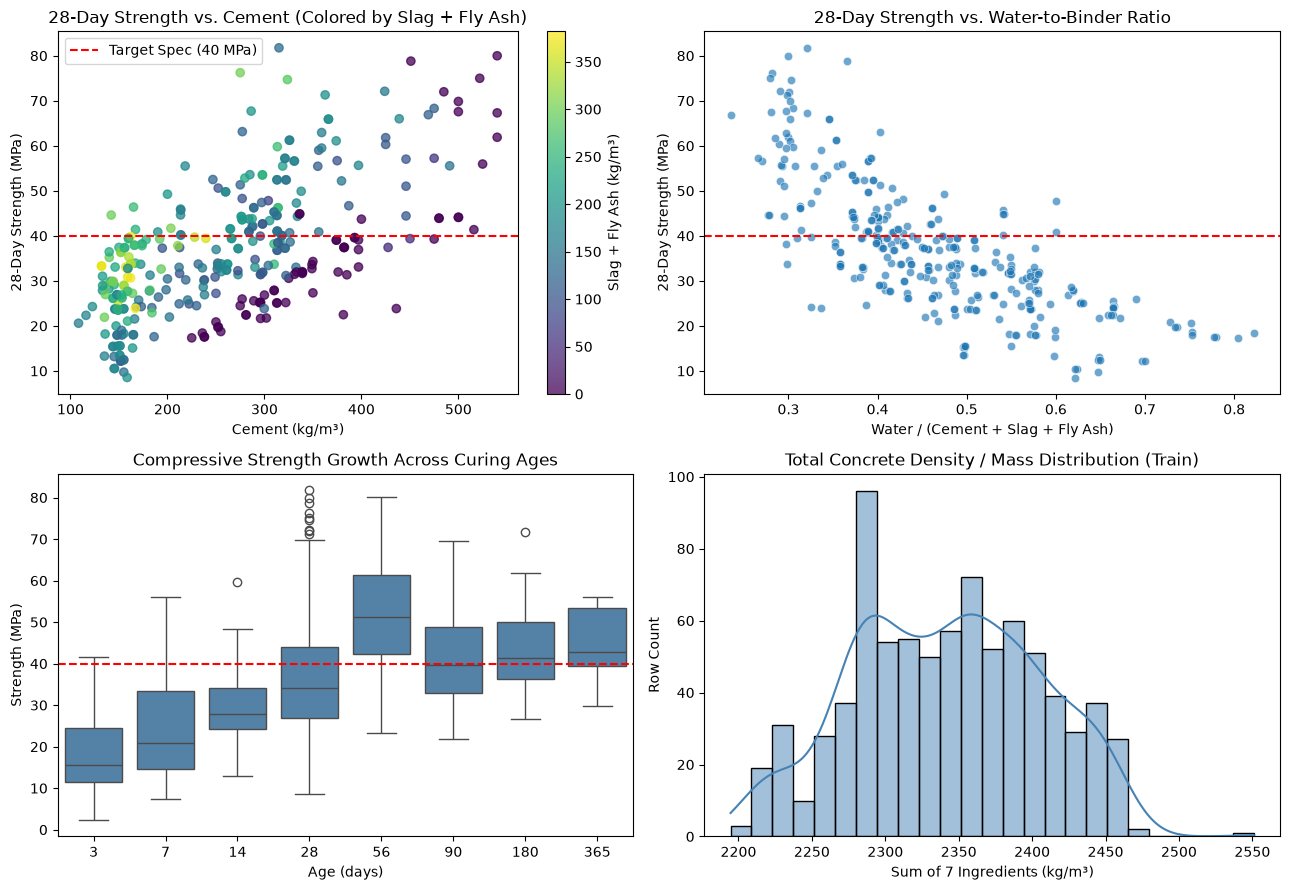

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Plot 1: Cement vs 28-day Strength (colored by slag + fly ash)
train_28["scm_kg"] = (
    train_28["blast_furnace_slag_kg_per_m3"] + train_28["fly_ash_kg_per_m3"]
)
sc = axes[0, 0].scatter(
    train_28["cement_kg_per_m3"],
    train_28["compressive_strength_mpa"],
    c=train_28["scm_kg"],
    cmap="viridis",
    alpha=0.75,
)
axes[0, 0].axhline(40, color="red", linestyle="--", label="Target Spec (40 MPa)")
axes[0, 0].set_title("28-Day Strength vs. Cement (Colored by Slag + Fly Ash)")
axes[0, 0].set_xlabel("Cement (kg/m³)")
axes[0, 0].set_ylabel("28-Day Strength (MPa)")
axes[0, 0].legend()
plt.colorbar(sc, ax=axes[0, 0], label="Slag + Fly Ash (kg/m³)")

# Plot 2: Water-to-Binder Ratio vs 28-day Strength
sns.scatterplot(
    data=train_28,
    x="water_binder_ratio",
    y="compressive_strength_mpa",
    alpha=0.65,
    ax=axes[0, 1],
)
axes[0, 1].axhline(40, color="red", linestyle="--")
axes[0, 1].set_title("28-Day Strength vs. Water-to-Binder Ratio")
axes[0, 1].set_xlabel("Water / (Cement + Slag + Fly Ash)")
axes[0, 1].set_ylabel("28-Day Strength (MPa)")

# Plot 3: Curing Age vs Strength (shows why age_days matters)
sns.boxplot(
    data=train[train["age_days"].isin([3, 7, 14, 28, 56, 90, 180, 365])],
    x="age_days",
    y="compressive_strength_mpa",
    color="steelblue",
    ax=axes[1, 0],
)
axes[1, 0].axhline(40, color="red", linestyle="--")
axes[1, 0].set_title("Compressive Strength Growth Across Curing Ages")
axes[1, 0].set_xlabel("Age (days)")
axes[1, 0].set_ylabel("Strength (MPa)")

# Plot 4: Total Mass Distribution (kg/m3)
sns.histplot(train_all_mass, bins=25, kde=True, color="steelblue", ax=axes[1, 1])
axes[1, 1].set_title("Total Concrete Density / Mass Distribution (Train)")
axes[1, 1].set_xlabel("Sum of 7 Ingredients (kg/m³)")
axes[1, 1].set_ylabel("Row Count")

plt.tight_layout()
plt.show()

1. 28-Day Strength vs. Cement (Colored by Slag + Fly Ash)

Dark purple dots (mixes with zero slag and fly ash) climb steadily upward as cement increases, needing about 350 to 540 kg/m³ of cement to reach the red 40 MPa target line.

On the left side (140 to 200 kg/m³ of cement), almost all dots sit below the red 40 MPa target line (mostly between 10 and 38 MPa). Only a few rare mixes reach above 40 MPa in this low-cement zone, and every single one of them is bright green, showing that reaching 40 MPa with low cement is difficult and requires replacing cement with large amounts of blast furnace slag and fly ash (around 200 to 300 kg/m³ combined) plus low water.

2. 28-Day Strength vs. Water-to-Binder Ratio

As the water-to-binder ratio increases from left to right (from 0.25 to 0.80), concrete strength drops sharply in a clear downward curve.

Almost every mix that reaches the red 40 MPa line has a water-to-binder ratio between 0.28 and 0.48. Above 0.55, almost no mixes reach 40 MPa. To hit 40 MPa with low cement, optimizer must keep water low relative to total binder (using superplasticizer to help).

3. Compressive Strength Growth Across Curing Ages

Median strength climbs steadily from 16 MPa at 3 days to 21 MPa at 7 days, 28 MPa at 14 days, and 34 MPa at 28 days (with strong mixes reaching 40 to 82 MPa at 28 days).

Because curing age strongly drives strength, keeping all ages in our training data lets the model learn the full strength-growth curve, while fixing age_days = 28 during validation and optimization matches our 28-day lab test rule.

4. Total Concrete Density / Mass Distribution (Train)

Almost all concrete mixes weigh between 2,200 kg/m³ and 2,470 kg/m³, peaking around 2,290 to 2,360 kg/m³ (with one rare outlier near 2,550 kg/m³).   

Because 1 m³ of concrete must fit a fixed volume, we should constrain the sum of all 7 ingredients in our optimizer to stay within the realistic training range (2,229 to 2,449 kg/m³, the central 90% of the data) so the model does not invent impossible, overly light or overly heavy mixes.

# Modelling

Why Use Ridge Regression + These 4 Tree Models:
- Ridge Regression (Linear Baseline): Fits a simple straight-line formula across the ingredients and age. It acts as our starting benchmark to prove whether concrete strength truly needs more complex non-linear models.
- Random Forest: Builds many independent decision trees and averages their guesses. It is stable, hard to overfit, and handles curved patterns well.
- XGBoost: Builds trees one after another, where each new tree fixes the errors of the previous ones. It is very strong at capturing complex interactions between concrete ingredients and curing age.
- LightGBM: Also builds trees step-by-step like XGBoost, but grows them faster by splitting the most important data points first. It is lightweight and fast to tune.
- CatBoost: Builds balanced (symmetric) trees that reduce overfitting on small datasets like this one (810 training rows).

Why Use RMSE and MAE?
- MAE (Mean Absolute Error) - Typical Error: MAE calculates the simple average size of all errors, ignoring whether the guess was too high or too low. It tells the materials team what error to expect on a normal, everyday prediction.

- RMSE (Root Mean Squared Error) - Large Mistake Penalty: RMSE squares each error before averaging, which punishes big mistakes much more heavily than small ones. This is critical for concrete mix design because a model that is usually close (3 MPa off) but occasionally makes a huge mistake (12 MPa off) could trick the team into casting a weak concrete batch that fails the 40 MPa lab test.

Standard Deviation (±): Showing the ± spread across the 5 validation splits tells the team whether the model performs steadily across all concrete recipes or fails wildly on certain unseen mixes.

Both metrics measure prediction error directly in megapascals (MPa).

Cross-validation compares Ridge Regression, Random Forest, XGBoost, LightGBM, and CatBoost only on the training set (evaluated specifically on 28-day rows to match our optimization goal). Keeping the final test set locked away until the very end ensures our final score is honest and unbiased.

In [21]:
features = [
    "cement_kg_per_m3",
    "blast_furnace_slag_kg_per_m3",
    "fly_ash_kg_per_m3",
    "water_kg_per_m3",
    "superplasticizer_kg_per_m3",
    "coarse_aggregate_kg_per_m3",
    "fine_aggregate_kg_per_m3",
    "age_days",
]
target = "compressive_strength_mpa"

x_train = train[features]
y_train = train[target]
groups_train = train["recipe_id"]

x_test = test[features]
y_test = test[target]
test_28_mask = test["age_days"] == 28

In [24]:
# Define baseline model (Ridge) + 4 tree models
models = {
    "Ridge (Linear Baseline)": Pipeline(
        [("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]
    ),
    "Random Forest": RandomForestRegressor(random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    "CatBoost": CatBoostRegressor(random_seed=42, verbose=0),
}

# 5-Fold GroupKFold: train on all ages, evaluate strictly on age_days == 28
gkf = GroupKFold(n_splits=5)
results = []

In [25]:
for name, model in models.items():
  fold_rmse, fold_mae = [], []

  for tr_idx, va_idx in gkf.split(x_train, y_train, groups=groups_train):
    x_tr, y_tr = x_train.iloc[tr_idx], y_train.iloc[tr_idx]
    x_va, y_va = x_train.iloc[va_idx], y_train.iloc[va_idx]

    model.fit(x_tr, y_tr)

    # Score only on 28-day rows in validation fold
    va_28 = x_va["age_days"] == 28
    preds_va = model.predict(x_va[va_28])
    fold_rmse.append(root_mean_squared_error(y_va[va_28], preds_va))
    fold_mae.append(mean_absolute_error(y_va[va_28], preds_va))

  # Fit on full train set and score on held-out 28-day test rows
  model.fit(x_train, y_train)
  preds_test_28 = model.predict(x_test[test_28_mask])

  results.append({
      "Model": name,
      "28d CV RMSE (MPa)": f"{np.mean(fold_rmse):.2f} ± {np.std(fold_rmse):.2f}",
      "28d CV MAE (MPa)": f"{np.mean(fold_mae):.2f} ± {np.std(fold_mae):.2f}",
      "28d Test RMSE (MPa)": (
          f"{root_mean_squared_error(y_test[test_28_mask], preds_test_28):.2f}"
      ),
      "28d Test MAE (MPa)": (
          f"{mean_absolute_error(y_test[test_28_mask], preds_test_28):.2f}"
      ),
  })

results_df = pd.DataFrame(results)
print("Baseline Model Comparison (Evaluated on 28-Day Strength):")
print(results_df.to_string(index=False))

Baseline Model Comparison (Evaluated on 28-Day Strength):
                  Model 28d CV RMSE (MPa) 28d CV MAE (MPa) 28d Test RMSE (MPa) 28d Test MAE (MPa)
Ridge (Linear Baseline)       8.97 ± 0.88      6.73 ± 0.50                7.88               5.93
          Random Forest       6.57 ± 0.99      4.39 ± 0.52                6.00               4.48
                XGBoost       6.50 ± 1.06      4.22 ± 0.63                5.78               3.91
               LightGBM       6.49 ± 0.95      4.26 ± 0.49                6.01               4.22
               CatBoost       6.28 ± 0.91      4.12 ± 0.57                5.12               3.49


Ridge Regression (Linear Baseline - Weakest Performance): Ridge Regression has the highest error by far (28d CV RMSE: 8.97 ± 0.88 MPa, 28d CV MAE: 6.73 ± 0.50 MPa, 28d Test RMSE: 7.88 MPa). Because concrete strength depends on curved age growth and complex interactions between water, cement, and by-product binders, a simple straight-line formula cannot fit the data well.

Random Forest (Strong Non-Linear): Switching to Random Forest cuts the validation RMSE by 2.40 MPa (down to 6.57 ± 0.99 MPa, with Test RMSE: 6.00 MPa). This proves that non-linear tree models are necessary to capture ingredient interactions.

XGBoost (Good Accuracy, Highest Spread): XGBoost improves validation accuracy slightly over Random Forest (28d CV RMSE: 6.50 ± 1.06 MPa, 28d CV MAE: 4.22 ± 0.63 MPa, 28d Test MAE: 3.91 MPa). However, it has the largest fold-to-fold spread (± 1.06 MPa), meaning its error fluctuates more depending on which concrete recipes are held out.

LightGBM (Second-Best Overall & Steady): LightGBM achieves the second-lowest validation RMSE (6.49 ± 0.95 MPa, with 28d CV MAE: 4.26 ± 0.49 MPa) and tight fold consistency (± 0.49 MPa MAE), making it a strong candidate for hyperparameter tuning.

CatBoost (Best Overall Performance): CatBoost achieves the lowest error across every single metric on both cross-validation and the held-out test set (28d CV RMSE: 6.28 ± 0.91 MPa, 28d CV MAE: 4.12 ± 0.57 MPa, 28d Test RMSE: 5.12 MPa, 28d Test MAE: 3.49 MPa). Its symmetric tree structure handles this 810-row training dataset well without overfitting.

Conclusion:   
Based on the 28-day cross-validation results, CatBoost is the top performer for predicting concrete compressive strength, achieving the lowest error across both cross-validation (6.28 ± 0.91 MPa RMSE, 4.12 ± 0.57 MPa MAE) and the test set (5.12 MPa RMSE, 3.49 MPa MAE). Because CatBoost already provides strong, balanced accuracy without adding extra model complexity, I choose it as main model for the mix optimization search.

In [ ]:
# Add prediction uncertainty to CatBoost
n_models = 30
catboost_ensemble = []
unique_recipes = train["recipe_id"].unique()
rng = np.random.default_rng(42)  # Fixed seed so results stay the same

for i in range(n_models):
  # Pick random recipes with replacement (keeps all ages of a recipe together)
  sampled_recipes = rng.choice(
      unique_recipes, size=len(unique_recipes), replace=True
  )

  # Build the training sample for this model
  boot_train = pd.concat(
      [train[train["recipe_id"] == r] for r in sampled_recipes],
      ignore_index=True,
  )

  # Train one CatBoost model
  model = CatBoostRegressor(random_seed=42 + i, verbose=0)
  model.fit(boot_train[features], boot_train[target])
  catboost_ensemble.append(model)

print(f"Trained {len(catboost_ensemble)} CatBoost models for uncertainty")


# Helper function to predict strength + uncertainty for any new mix
def predict_with_uncertainty(X_input):
  # Collect predictions from all 30 models
  all_preds = np.array([model.predict(X_input) for model in catboost_ensemble])

  mean_pred = np.mean(all_preds, axis=0)  # Average strength (MPa)
  std_pred = np.std(all_preds, axis=0)  # Uncertainty (+/- MPa)
  return mean_pred, std_pred

Trained 30 CatBoost models for uncertainty.


In [ ]:
# Test on 28-day test rows
test_28 = x_test[test_28_mask]
mean_strength, uncertainty = predict_with_uncertainty(test_28)

for i in range(5):
  actual = y_test[test_28_mask].iloc[i]
  print(
      f"Test Mix {i+1}: Predicted = {mean_strength[i]:.2f} ±"
      f" {uncertainty[i]:.2f} MPa | Actual = {actual:.2f} MPa"
  )

Test Mix 1: Predicted = 38.48 ± 1.77 MPa | Actual = 36.45 MPa
Test Mix 2: Predicted = 39.12 ± 2.17 MPa | Actual = 45.85 MPa
Test Mix 3: Predicted = 55.04 ± 2.16 MPa | Actual = 50.70 MPa
Test Mix 4: Predicted = 61.20 ± 3.73 MPa | Actual = 56.40 MPa
Test Mix 5: Predicted = 61.37 ± 2.13 MPa | Actual = 68.50 MPa


Predicted number = average strength guess from 30 catboost model.   
± = How much the 30 models disagree with each other. A small number means the models agree. A large number means the mix is unfamiliar, so the models are less sure.

What these 5 examples tell:   
In Test Mix 1, the models agree closely (± 1.77 MPa), and the prediction (38.48 MPa) is close to the real result (36.45 MPa). In Test Mix 4, the uncertainty is twice as wide (± 3.73 MPa), showing that the training data has fewer similar recipes in that region.

In Test Mix 2, the models agreed within ± 2.17 MPa, yet the actual strength was 45.85 MPa (6.73 MPa higher than predicted). This happens because concrete mixing has natural laboratory noise (even identical recipes vary slightly when crushed).   

Why this matters for optimizer:   
The 40 MPa rule in Scenario S1 applies to the real concrete when the laboratory crushes it after 28 days. However, the CatBoost model only makes a prediction, not an exact measurement. On unseen test mixes, the model has a prediction error (test RMSE) of 5.12 MPa. Because the real concrete can be weaker than the model predicts, aiming for 40.1 MPa is too risky.

Suppose the optimizer finds a low-cement mix and predicts a strength of 40.1 MPa. Inside the computer, 40.1 MPa passes the 40 MPa rule. However, real laboratory tests can be weaker than computer predictions. In our earlier test results, Test Mix 4 had a predicted strength of 61.20 MPa, but its real strength in the lab was only 56.40 MPa. That is 4.80 MPa lower than predicted. If the same 4.80 MPa drop happens to our 40.1 MPa mix, its real strength will be only 35.3 MPa. The concrete will fail the 40 MPa test, and we will waste one of our three limited laboratory slots

So we tell the optimizer to aim higher, such as requiring a predicted strength of at least 45.0 MPa. If the model predicts 45.0 MPa and the real concrete turns out 4.80 MPa weaker, the real strength is still 40.2 MPa. The mix passes the 40 MPa target in the real lab.

# Optimization

Objective Function:   
Make the amount of cement (cement_kg_per_m3) as low as possible.

$$\min_{x_1, x_2, \dots, x_7} \; x_1 \quad (\text{cement in kg/m}^3)$$

Decision Variable:   
1. x1 = cement_kg_per_m3 - Main binder (glue)
2. x2 = blast_furnace_slag_kg_per_m3 - Industrial by-product binder
3. x3 = fly_ash_kg_per_m3 - Coal by-product binder
4. x4 = water_kg_per_m3 - Mixing water
5. x5 = superplasticizer_kg_per_m3 - Liquid additive that reduces water need
6. x6 = coarse_aggregate_kg_per_m3 - Gravel or crushed stone
7. x7 = fine_aggregate_kg_per_m3 - Sand


Fixed Quantity:   
- Curing age (age_days): Fixed at 28 days, because every candidate mix is crushed after 28 days in the lab.
- Strength prediction model: The trained 30-model CatBoost ensemble is fixed during the search and predicts the average 28-day strength ($\hat{\mu}$) and model uncertainty ($\hat{\sigma}$).


Constraints:  
| **Constraint / Bound** | **Rule / Formula** | **Source** | **Short Justification** |
|---|---|---|---|
| **Individual Ingredient Bounds** | $\text{Train Min}_i \le x_i \le \text{Train Max}_i$ (or 1st–99th percentile) for all 7 ingredients | Data-derived (train split) | Tree models like CatBoost cannot make reliable predictions outside the ingredient ranges seen in the training data. |
| **Total Mix Mass (Density)** | $2,229 \le \sum_{i=1}^{7} x_i \le 2,449\text{ kg/m}^3$ | Data-derived (5th–95th percentile of train data) | One cubic meter of concrete has a fixed physical volume. This rule prevents mixes that are too light or too heavy to fill $1\text{ m}^3$. |
| **Water-to-Binder Ratio** | $0.29 \le \frac{x_4}{x_1 + x_2 + x_3} \le 0.67$ | Data-derived (5th–95th percentile of train data) | Too much water creates weak concrete, while too little water makes the mix too dry to stir properly in the lab. |
| **Total Binder Limit** | $x_1 + x_2 + x_3 \le \text{Train Max Total Binder}$ | Data-derived (train split) | Stops the optimizer from stacking unrealistic amounts of slag and fly ash at the same time. |
| **Target 28-Day Strength** | $\text{Real Strength} \ge 40.0\text{ MPa}$ | Scenario Assumption (S1) | Every candidate mix must reach at least $40\text{ MPa}$ when crushed after 28 days. |
| **Model Safety Buffer** | $\hat{\mu}_{28} \ge 45.0\text{ MPa}$ (or $\hat{\mu}_{28} - 1\hat{\sigma}_{28} \ge 40.0\text{ MPa}$) | Assumption (based on $5.12\text{ MPa}$ CatBoost test RMSE) | Protects against model prediction error so the real concrete still passes the $40\text{ MPa}$ test in the lab. |
| **Laboratory Testing Limit** | $\text{Number of selected mixes} \le 3$ | Scenario Assumption (S4) | The laboratory only has budget and time to cast and test at most three mixes. |

## Optimization Search

In [29]:
# Set data-derived bounds (min and max from training data for each of the 7 ingredients)
bounds = [(train[col].min(), train[col].max()) for col in ingredient_cols]
max_total_binder = (
    train["cement_kg_per_m3"]
    + train["blast_furnace_slag_kg_per_m3"]
    + train["fly_ash_kg_per_m3"]
).max()

CatBoost uses decision trees, so its predictions jump in flat steps instead of smooth lines.
Basic search methods get stuck on flat steps because they need smooth lines to find the best answer. Differential Evolution works well on flat steps because it tests many recipes at the same time. Setting a fixed random seed also makes sure the code finds the exact same mixes every time it runs.

In [30]:
# Function to run the search for a chosen strength target
def find_low_cement_mix(target_strength_mpa, seed=42):

  def objective(x):
    cement = x[0]
    slag = x[1]
    fly_ash = x[2]
    water = x[3]

    total_mass = np.sum(x)
    total_binder = cement + slag + fly_ash
    wb_ratio = water / total_binder

    # Add big penalties if any physical constraint is broken
    penalty = 0.0
    if total_mass < 2229.0:
      penalty += 1000 * (2229.0 - total_mass)
    if total_mass > 2449.0:
      penalty += 1000 * (total_mass - 2449.0)
    if wb_ratio < 0.29:
      penalty += 10000 * (0.29 - wb_ratio)
    if wb_ratio > 0.67:
      penalty += 10000 * (wb_ratio - 0.67)
    if total_binder > max_total_binder:
      penalty += 1000 * (total_binder - max_total_binder)

    # Predict 28-day strength using the 30-model CatBoost ensemble
    mix_df = pd.DataFrame([list(x) + [28]], columns=features)
    mean_pred, _ = predict_with_uncertainty(mix_df)

    # Penalty if predicted strength is below our safety target
    if mean_pred[0] < target_strength_mpa:
      penalty += 5000 * (target_strength_mpa - mean_pred[0])

    return cement + penalty

  # Run reproducible search
  result = differential_evolution(
      objective,
      bounds=bounds,
      seed=seed,
      maxiter=150,
      popsize=15,
      polish=False,
  )

  best_x = np.round(result.x, 1)
  mix_df = pd.DataFrame([list(best_x) + [28]], columns=features)
  mean_pred, std_pred = predict_with_uncertainty(mix_df)
  return best_x, mean_pred[0], std_pred[0]

In [31]:
# Search for 3 distinct mixes (Safe, Balanced, Aggressive)
targets = [46.0, 44.0, 42.5]
candidates = []

for i, t in enumerate(targets):
  mix, pred, unc = find_low_cement_mix(target_strength_mpa=t, seed=42 + i)
  candidates.append((t, mix, pred, unc))
  print(
      f"Mix {i+1} (Target >= {t} MPa): Cement = {mix[0]} kg/m³ | Predicted"
      f" Strength = {pred:.2f} ± {unc:.2f} MPa"
  )

Mix 1 (Target >= 46.0 MPa): Cement = 108.6 kg/m³ | Predicted Strength = 46.48 ± 3.88 MPa
Mix 2 (Target >= 44.0 MPa): Cement = 108.3 kg/m³ | Predicted Strength = 44.43 ± 4.81 MPa
Mix 3 (Target >= 42.5 MPa): Cement = 108.3 kg/m³ | Predicted Strength = 42.94 ± 4.54 MPa


All three searches pushed cement down to around 108.3 to 108.6 kg/m³, which is near the lowest cement value in the training data.   

Mix 1 uses almost the exact same amount of cement as Mix 2 and Mix 3 (108.6 vs. 108.3 kg/m³, a tiny 0.3 kg/m³ difference). However, Mix 1 gives higher predicted strength (46.48 MPa) and lower model uncertainty (± 3.88 MPa).

Mix 2 and Mix 3 save almost no extra cement compared to Mix 1, yet they carry higher uncertainty (± 4.81 MPa and ± 4.54 MPa) and sit closer to the 40 MPa failure line.   

### Compare Strength Against Baseline

The baseline is the best existing concrete recipe in the dataset that already passes the 40 MPa requirement at 28 days.

Baseline Cement: 141.90 kg/m³ (the lowest cement amount among all 141 passing 28-day mixes).   Baseline Strength: 44.61 MPa (real crushing strength measured in the laboratory at 28 days).

<br>

| **Mix Name** | **Cement (kg/m³)** | **Cement Saved vs. Baseline (kg/m³)** | **Cement Saved (%)** | **28-Day Strength (MPa)** | **Buffer Above 40 MPa Spec** |
|---|---:|---:|---:|---:|---:|
| **Baseline (Best Existing Mix)** | 141.90 | 0.00 | 0.0% | 44.61 (Measured) | +4.61 MPa |
| **Mix 1 (Recommended Best)** | 108.60 | -33.30 | -23.5% | 46.48 ± 3.88 (Predicted) | +6.48 MPa |
| **Mix 2** | 108.30 | -33.60 | -23.7% | 44.43 ± 4.81 (Predicted) | +4.43 MPa |
| **Mix 3** | 108.30 | -33.60 | -23.7% | 42.94 ± 4.54 (Predicted)| +2.94 MPa|

Mix 1 has a predicted strength of 46.48 MPa, which is 1.87 MPa higher than the baseline (44.61 MPa). Mix 2 (44.43 MPa) sits almost equal to the baseline, while Mix 3 (42.94 MPa) is 1.67 MPa weaker than the baseline.   

The baseline strength (44.61 MPa) is a real laboratory test result. The candidate strengths are model predictions with uncertainty (± 3.88 to ± 4.81 MPa). Because Mix 1 has the highest predicted strength and the smallest uncertainty (± 3.88 MPa), it has the best chance of passing the 40 MPa laboratory test.

In [33]:
unique_train_recipes = train[ingredient_cols].drop_duplicates()
scaler = StandardScaler()
train_scaled = scaler.fit_transform(unique_train_recipes)

# # Calculate the typical distance between real recipes in the training data for comparison
train_pairwise = cdist(train_scaled, train_scaled)
np.fill_diagonal(train_pairwise, np.inf)
median_train_dist = np.median(train_pairwise.min(axis=1))
print(
    "Typical distance between real training mixes:"
    f" {median_train_dist:.2f}\n"
)

# Get the best existing passing mix as the baseline
baseline_row = all_28_passing.iloc[0]

# Build the complete table with all 7 ingredients
table_rows = []

# Add Baseline row first
table_rows.append({
    "Mix": "Baseline (Best Existing)",
    "Cement (kg/m3)": round(baseline_row["cement_kg_per_m3"], 1),
    "Slag (kg/m3)": round(baseline_row["blast_furnace_slag_kg_per_m3"], 1),
    "Fly Ash (kg/m3)": round(baseline_row["fly_ash_kg_per_m3"], 1),
    "Water (kg/m3)": round(baseline_row["water_kg_per_m3"], 1),
    "Superplasticizer (kg/m3)": round(
        baseline_row["superplasticizer_kg_per_m3"], 1
    ),
    "Coarse Agg (kg/m3)": round(baseline_row["coarse_aggregate_kg_per_m3"], 1),
    "Fine Agg (kg/m3)": round(baseline_row["fine_aggregate_kg_per_m3"], 1),
    "28d Strength (MPa)": (
        f"{baseline_row['compressive_strength_mpa']:.2f} (Actual)"
    ),
    "Cement vs Baseline": "0.0 kg/m3 (0.0%)",
    "Nearest Train Dist": "0.00 (In Dataset)",
})

# Add the 3 Candidate Mixes
for i, (target_s, mix, pred, unc) in enumerate(candidates):
  # Calculate distance to nearest real recipe in training data
  mix_scaled = scaler.transform(
      pd.DataFrame([mix], columns=ingredient_cols)
  )
  distances = cdist(mix_scaled, train_scaled)[0]
  nearest_dist = distances.min()

  # Calculate cement saved vs baseline
  saved_kg = baseline_row["cement_kg_per_m3"] - mix[0]
  saved_pct = (saved_kg / baseline_row["cement_kg_per_m3"]) * 100

  table_rows.append({
      "Mix": f"Candidate Mix {i+1}",
      "Cement (kg/m3)": round(mix[0], 1),
      "Slag (kg/m3)": round(mix[1], 1),
      "Fly Ash (kg/m3)": round(mix[2], 1),
      "Water (kg/m3)": round(mix[3], 1),
      "Superplasticizer (kg/m3)": round(mix[4], 1),
      "Coarse Agg (kg/m3)": round(mix[5], 1),
      "Fine Agg (kg/m3)": round(mix[6], 1),
      "28d Strength (MPa)": f"{pred:.2f} ± {unc:.2f} (Pred)",
      "Cement vs Baseline": f"-{saved_kg:.1f} kg/m3 (-{saved_pct:.1f}%)",
      "Nearest Train Dist": f"{nearest_dist:.2f}",
  })

final_table = pd.DataFrame(table_rows)
print(final_table.to_string(index=False))

Typical distance between real training mixes: 0.31

                     Mix  Cement (kg/m3)  Slag (kg/m3)  Fly Ash (kg/m3)  Water (kg/m3)  Superplasticizer (kg/m3)  Coarse Agg (kg/m3)  Fine Agg (kg/m3)  28d Strength (MPa)   Cement vs Baseline Nearest Train Dist
Baseline (Best Existing)           141.9         166.6            129.7          173.5                      10.9               882.6             785.3      44.61 (Actual)     0.0 kg/m3 (0.0%)  0.00 (In Dataset)
         Candidate Mix 1           108.6         349.6             18.7          143.2                      11.1               829.6             774.4 46.48 ± 3.88 (Pred) -33.3 kg/m3 (-23.5%)               2.60
         Candidate Mix 2           108.3         285.6              1.5          144.2                      10.1              1137.8             630.2 44.43 ± 4.81 (Pred) -33.6 kg/m3 (-23.7%)               1.99
         Candidate Mix 3           108.3         195.0             48.0          152.6                  

Real concrete recipes in the training data sit very close together, with a typical distance of 0.31.

All three candidate mixes sit much farther away (1.77 to 2.60). This is 6 to 8 times farther than normal.

A large distance means the optimizer moved into empty regions of the data where no real laboratory tests exist. Because CatBoost has never seen recipes like these, the predictions rely on extrapolation rather than direct data support.

1. Candidate Mix 1 (2.60 distance): Cuts cement by 33.3 kg/m³ (23.5%) compared to the baseline. It achieves the highest predicted strength (46.48 MPa) and smallest uncertainty (± 3.88 MPa). However, it reaches this result by packing in an extreme amount of blast furnace slag (349.6 kg/m³, more than double the baseline's 166.6 kg/m³) and very low water (143.2 kg/m³). Because 2.60 is far from real training mixes, this recipe carries the highest extrapolation risk.    

2. Candidate Mix 2 (1.99 distance): Cuts cement by 33.6 kg/m³ (23.7%), but removes almost all fly ash (1.5 kg/m³) and pushes coarse gravel to the upper edge (1,137.8 kg/m³). Its uncertainty is the widest (± 4.81 MPa), making it risky to pass 40 MPa.   

3. Candidate Mix 3 (1.77 distance - Closest to Data): Cuts cement by 33.6 kg/m³ (23.7%) and sits closest to the training data among the three candidates. However, its predicted strength (42.94 ± 4.54 MPa) sits only 2.94 MPa above the 40 MPa limit. Because the model error is 5.12 MPa (test RMSE), Mix 3 has a high risk of falling below 40 MPa in the lab.   

## Possible Failure Cause:

1. Candidate Mix 1:

- Mix 1 uses an extreme amount of blast furnace slag (349.6 kg/m³, more than double the baseline's 166.6 kg/m³) to replace cement. Slag hardens more slowly than cement. If the lab slag reacts slowly, the concrete may not reach 40 MPa by day 28.

- Low water (143.2 kg/m³) combined with a high total binder weight (476.9 kg/m³) creates a very low water-to-binder ratio (0.30). The wet concrete may be too stiff to mix smoothly, trapping air pockets that weaken the cylinder.

2. Candidate Mix 2:

- Mix 2 has the largest model uncertainty (± 4.81 MPa). Because the model has a test error (RMSE) of 5.12 MPa, a 4.43 MPa safety buffer above 40 MPa can easily drop below 40 MPa in the lab.   

- Mix 2 pushes coarse stone near the maximum limit (1,137.8 kg/m³) while reducing sand (630.2 kg/m³). Without enough sand to fill the spaces between stones, empty gaps can form and cause early cracking under pressure.

3. Candidate Mix 3:

- Mix 3 sits closest to real training data (1.77 distance), making it the easiest recipe to mix. However, its predicted strength (42.94 MPa) sits only 2.94 MPa above the 40 MPa requirement. Given the 5.12 MPa model error and ± 4.54 MPa uncertainty, Mix 3 has the highest risk of falling short of 40 MPa when crushed.

## Out-of-Scope Factors That Matter in Practice (S5)

The dataset contains no measurements for these factors, and no numbers were invented for them. However, the laboratory team must check them before mixing:
- Workability: Low water (143–153 kg/m³) and high slag or coarse stone can make wet concrete too thick to pour into molds without leaving air holes.   
- Durability: Replacing over 70% of cement with slag and fly ash can reduce long-term resistance to surface scaling, freezing, or chemical wear.   
- Material types and grades: The data does not record the chemical grade of the cement, slag, fly ash, or superplasticizer. Different supplier batches react at different speeds.   
- Other ingredient costs and building codes: High doses of slag (349.6 kg/m³) and superplasticizer (11.4 kg/m³) increase material costs, and local building codes often restrict maximum slag percentages in structural concrete.   

# Lab Validation Plan

### How to Test

1. Mix the concrete batches. Make one test batch for each of the 3 recommended mixes. Make one extra control batch using the Baseline mix (141.9 kg/m³ cement). The control batch checks that the lab tools and materials work as expected.   
2. Pour 3 test cylinders per batch. Pour the wet concrete from each batch into 3 standard round molds. Testing 3 cylinders for each mix shows normal lab variation, just like the repeat tests in the dataset.   
3. Check how the wet mix flows. Measure how easily the wet concrete flows (called a slump test) before pouring. This catches dry or stiff mixes early, even though flow is outside the model scope.   
4. Cure and crush at 28 days. Keep all cylinders at the same standard heat and moisture for 28 days. After 28 days, crush each cylinder in the press machine to measure its strength in MPa. 


### What Confirms or Rejects a Mix

Confirm (Pass): The average strength of the 3 cylinders is 40.0 MPa or higher at 28 days. Also, the cylinders must look solid with no big air holes or crumbling edges.

Reject (Fail): The average strength of the 3 cylinders is below 40.0 MPa at 28 days. A mix also fails if it is too dry to mix and pour into a solid cylinder.


### How Results Improve the Next Round

Add all new 28-day test results (both passing and failing mixes) into the training data. Train the 30 CatBoost models again so the model learns how real low-cement mixes (~108 kg/m³) perform.

Change the search rules for Round 2:
- If at least one mix passes (40.0 MPa or higher): Pick the passing mix with the lowest cement as the new baseline. Search for small recipe changes near that mix to make sure it passes every time.   
- If all three mixes fail (below 40.0 MPa): Raise the lowest allowed cement amount in the search (for example, to 120–130 kg/m³). Also add a rule that keeps new mixes closer to real recipes in the training data.   